In [2]:
import numpy as np
import torch
import os
import glob

In [ ]:
import pandas as pd

script_file_path = 'bash_scripts/test.sh'
watch_list = []
with open(script_file_path, 'r', encoding='utf-8') as f:
    for line in f:
        if not line.startswith('for'):
            continue
        watch = line.split('in')[-1].split()
        watch_list.extend(watch)
print(watch_list)

# Load the config file into a DataFrame
config_file_path = 'bash_scripts/config/test.csv'
df = pd.read_csv(config_file_path)

# Strip leading and trailing spaces from column names
df.columns = df.columns.str.strip()
# Strip leading and trailing spaces from all entries
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# Iterate over each row in the DataFrame
for idx, row in df.iterrows():
    ckpt_path = f'ckpt/{row["dataset"]}_{row["usage"]}/{row["model"]}_{row["depth"]}/{row["lr"]}_{row["snr"]}_{row["snvr"]}'
    seeds = row["seed"].split(';')

    best_accs = []
    for seed in seeds:
        seed_path = os.path.join(ckpt_path, seed)
        best_epoch_path = os.path.join(seed_path, 'best_epoch.pth')
        if not os.path.exists(best_epoch_path):
            break
        best_epoch = torch.load(best_epoch_path)

    if len(best_accs) == len(seeds):
        mean_acc = np.mean(best_accs)
        std_acc = np.std(best_accs)
        df.at[idx, 'accuracy'] = f'{mean_acc:.2f} ± {std_acc:.2f}'
    
df.to_csv(config_file_path, index=False)

['4', '5', '6', '7', '8', '9']
OrderedDict([('features.0.weight', tensor([[[[-0.0497, -0.3215, -0.0612],
          [-0.0116, -0.2231, -0.3807],
          [ 0.1796,  0.0799,  0.5683]],

         [[ 0.0450,  0.2954, -0.0388],
          [ 0.2728, -0.2718,  0.1811],
          [-0.1590, -0.0376,  0.1456]],

         [[ 0.3591,  0.1032, -0.2866],
          [ 0.2193, -0.3413,  0.0414],
          [-0.4518,  0.0636,  0.0168]]],


        [[[ 0.0894, -0.0089,  0.5671],
          [ 0.1648, -0.1443, -0.3892],
          [-0.4411,  0.3709, -0.0239]],

         [[ 0.7750, -0.2908,  0.1248],
          [ 0.0248, -0.1400, -0.1997],
          [-0.3970,  0.1604,  0.1300]],

         [[-0.1565,  0.2405, -0.1056],
          [ 0.0793, -0.5130, -0.0630],
          [-0.3192, -0.0323, -0.0263]]],


        [[[ 0.1476,  0.1078,  0.4297],
          [ 0.0286,  0.0655, -0.0210],
          [-0.5371, -0.3751, -0.3594]],

         [[-0.1491, -0.0632, -0.0810],
          [ 0.4182,  0.0787,  0.1237],
          [-0.1309,

In [204]:
ckpt = np.load('ckpt/cifar100/usage0.2/vgg_cifar_16_1/SGDSNR_init0.05_cosine/snr_sg0.005_snvr_svg0/epochs200_wd0.0005_seed43/training_stats.npy', allow_pickle=True).item()
ckpt['elapsed_time'][-1]/60


16.59701553185781

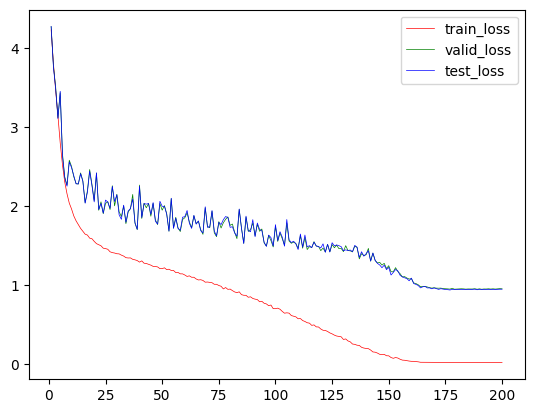

dict_keys(['train_loss', 'train_acc', 'valid_loss', 'valid_acc', 'test_loss', 'test_acc', 'current_lr', 'schedule_next_lr', 'epoch_time', 'elapsed_time', 'train_idx', 'valid_idx'])


In [ ]:

import matplotlib.pyplot as plt

ckpt = np.load('ckpt/cifar100/resnet_34_1/SGDSNR_init0.1_cosine/snr_sg0.015_snvr_svg1.0/epochs200_wd0.0005_seed43/training_stats.npy', allow_pickle=True).item()

loss_names = ['train_loss', 'valid_loss', 'test_loss']
colors = 'rgb'

for idx, loss_name in enumerate(loss_names):
    y = ckpt[loss_name]
    x = np.arange(1, len(y)+1)
    plt.plot(x, y, c=colors[idx], label=loss_name, alpha=1, linewidth=0.5)
plt.legend()
plt.show()

print(ckpt.keys())

Initialize the VGG by default width factor 1
0.7030010759557024
Initialize the VGG by default width factor 1
0.3158487204766713
Initialize the VGG by default width factor 1
0.25574025996846783


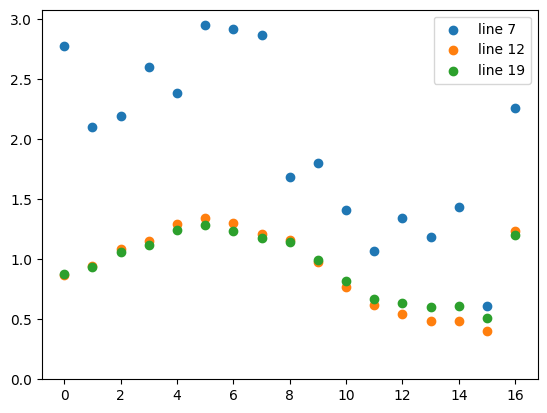

In [145]:
from networks import *
from sgdsnr import compute_weight
import matplotlib.pyplot as plt

watch_list = [7,12,19]

config_file_path = 'bash_scripts/config/test.tsv'
new_f = []
with open(config_file_path, 'r', encoding='utf-8') as f:
    for idx, line in enumerate(f):
        if idx+1 not in watch_list:
            continue

        line = line.replace('\t\t','\t')
        cols = line.split('\t')  # 탭으로 분리
        ckpt_path = f'ckpt/{cols[3]}/usage{cols[4]}/{cols[0]}_{cols[2]}_{cols[1]}/{cols[12]}_init{cols[8]}_{cols[6]}/snr_sg{cols[10]}_snvr_svg{cols[11]}'
        seeds = cols[7].split(',')

        best_accs = []
        for root, dirs, files in os.walk(ckpt_path):
            if 'training_stats.npy' not in files:
                continue
            ckpt = torch.load(os.path.join(root, 'epoch_best.ckpt'))
            break

        model = VGG_cifar(19, 100, 1)
        model.load_state_dict(ckpt['net'])
        model.cuda()

        sn_list = []
        for i, p in enumerate(model.parameters()):
            if p.dim() > 1:
                sn, uv = compute_weight(p, n_power_iterations=10)
                sn_list.append(sn.flatten()[0].item())
            else:
                pass
        print(np.std(sn_list))
        plt.scatter(range(len(sn_list)), sn_list, label=f'line {idx+1}')
plt.ylim(0.0)
plt.legend()
plt.show()